In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [4]:
df = pd.read_csv("WineDataset.csv")

In [7]:
columns = [
    'Customer_Segment', 'Alcohol', 'Malic_Acid', 'Ash',
    'Ash_Alcanity', 'Magnesium', 'Total_Phenols',
    'Flavanoids', 'Nonflavanoid_Phenols',
    'Proanthocyanins', 'Color_Intensity', 'Hue',
    'OD280', 'Proline'
]

df = pd.read_csv('wine.data', header=None, names=columns)

In [8]:
X = df.drop("Customer_Segment", axis=1)
y = df["Customer_Segment"]

In [9]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [10]:
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

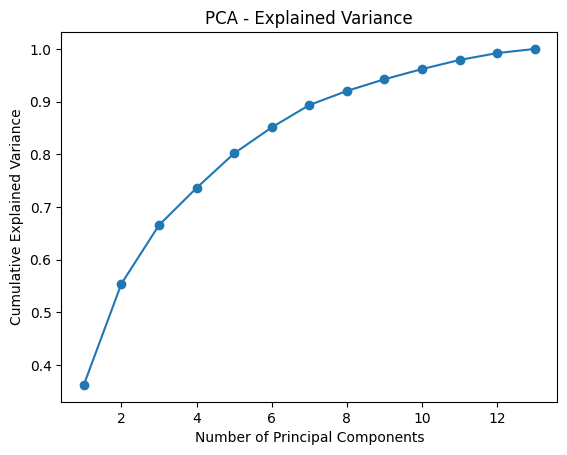

In [11]:
plt.plot(
    range(1, len(pca.explained_variance_ratio_) + 1),
    pca.explained_variance_ratio_.cumsum(),
    marker="o"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Explained Variance")
plt.show()

In [12]:
pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X_scaled)

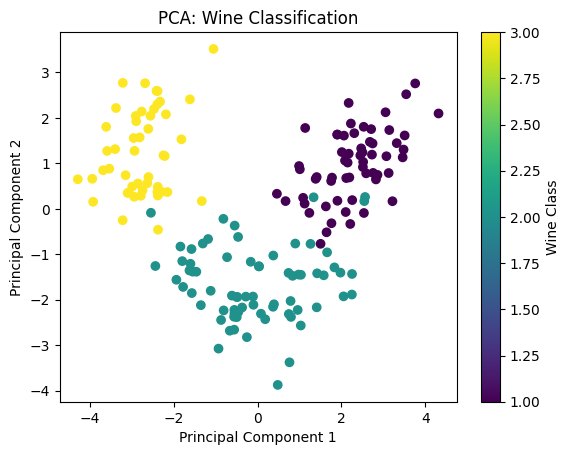

In [13]:
plt.scatter(
    X_reduced[:, 0], X_reduced[:, 1],
    c=y, cmap="viridis"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA: Wine Classification")
plt.colorbar(label="Wine Class")
plt.show()

In [14]:
print("Original shape:", X.shape)
print("Reduced shape:", X_reduced.shape)
print("Explained variance:", pca.explained_variance_ratio_)
print("Total variance retained:",
      pca.explained_variance_ratio_.sum())

Original shape: (178, 13)
Reduced shape: (178, 2)
Explained variance: [0.36198848 0.1920749 ]
Total variance retained: 0.5540633835693527
